# Information Diamond - Machine Learning Assignment

This is the machine learning assignment of the **Information Diamond**.  
This exercise will guide you step-by-step through the **machine learning workflow**, from exploring your dataset to training, testing, and evaluating a predictive model.

## Learning Goals

By the end of this notebook, you will be able to:

-  Explore and understand a dataset using [**pandas**](https://pandas.pydata.org/)
-  Perform **feature encoding** and **scaling**
-  Train and test a **K-Nearest Neighbors (KNN)** model using [**scikit-learn**](https://scikit-learn.org/)
-  Evaluate model performance and visualize results with [**matplotlib**](https://matplotlib.org/)
-  Save and reload your trained model for future inference

> You will apply these concepts in your **own ML project** starting on **Thursday**.


## Step 1 - Reading the Dataset

To begin, we’ll load our dataset using the **pandas** library.  
Pandas is a Python library for working with tabular data: it reads, explores, and transforms datasets.

Documentation: [pandas.read_csv()](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)

Run the code cell below to read the dataset and store it in a variable called `dataset`.


In [1]:
import pandas as pd
import seaborn as sns

#Modify the path according to where the file is in your filesystem
dataset_path = "StudentPerformanceFactors.csv" 

dataset = pd.read_csv(dataset_path)

## Step 2 - Exploring the Dataset

Before building any machine learning model, it is important to understand the data you are working with.  
Exploring the dataset helps you identify what kinds of variables it contains, check for missing values, and get a general sense of its structure.

Key pandas functions you can use:
- [DataFrame.shape](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html): shows the number of rows and columns.
- [DataFrame.columns](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.columns.html): lists all column names.
- [DataFrame.head()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html): displays the first few rows of the dataset.


In [2]:
# Show number of rows and columns in our dataset
print("Number of rows and columns:", dataset.shape)

# Show the column names
print("\nColumn names:")
for col in dataset.columns:
    print(" -", col)

# Inspect the first few rows of the data, to have a clearer idea about the data formats
print("\nPreview of the data:")
dataset.head()

Number of rows and columns: (6607, 20)

Column names:
 - Hours_Studied
 - Attendance
 - Parental_Involvement
 - Access_to_Resources
 - Extracurricular_Activities
 - Sleep_Hours
 - Previous_Scores
 - Motivation_Level
 - Internet_Access
 - Tutoring_Sessions
 - Family_Income
 - Teacher_Quality
 - School_Type
 - Peer_Influence
 - Physical_Activity
 - Learning_Disabilities
 - Parental_Education_Level
 - Distance_from_Home
 - Gender
 - Exam_Score

Preview of the data:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## Step 3 - Understanding the Variables

Now that we have seen the structure of the dataset, we look at what each column represents.

Each row corresponds to a single student, and each column describes one characteristic or factor that may influence the student's performance.  
For example:
- `Hours_Studied`: how many hours a student studied per week  
- `Attendance`: percentage of classes attended  
- `Parental_Involvement`: the level of support from parents  
- `Motivation_Level`: how motivated the student is  
- `Exam_Score`: the final score (this will be our target variable)

The goal of this exercise is to identify which factors are most strongly related to **Exam_Score** and then build a machine learning model that can predict it.

To start, we will explore some of these relationships using SQL queries in Python.


## Step 4 - Exploring the Dataset Using SQL Queries

In addition to pandas, we can use SQL queries to explore data in a more intuitive way.  
We will use the **pandasql** library, which allows you to run SQL queries directly on pandas DataFrames.

You can install the library using pip (if not already installed):

```python
!pip install pandasql
```

Then, import it and define a helper function that makes running queries easy:

```python
import pandasql as ps

def query(sql):
    return ps.sqldf(sql, globals())
```

Now you can query the `dataset` using SQL syntax.  
For example, to view the first few rows:

```python
query("SELECT * FROM dataset LIMIT 5;")
```

This approach suits anyone who is already familiar with SQL, since it performs grouping, filtering, and summarizing on the spot, before the data reaches the machine learning part.


In [3]:
#run this cell to install pandasql, you only have to run it once, then you can safely delete it
!pip install pandasql

In [4]:
import pandasql as ps

# function query(sql) will help us write our SQL queries easily
def query(sql):
    return ps.sqldf(sql, globals())

Try investigating one question at a time, and think:

Does this feature seem to have a strong influence on Exam_Score?

The first query is given below; it looks at whether gender has an impact on the final scores.

Your task is to investigate some of the remaining features.

In [5]:
print("Average exam score by gender:")
query("""
SELECT gender,
       AVG(Exam_Score) AS avg_exam_score
FROM dataset
GROUP BY gender;
""")


Average exam score by gender:


,Gender,avg_exam_score
0,Female,67.244898
1,Male,67.228894


As you can see above, gender doesn't indicate in any capacity the score of a student, so it's better to drop it.

### Exercise 1

Investigate how **Parental_Involvement** and **Parental_Education_Level** affect students’ exam scores.  


After running your query, reflect on the results:
- Which factor appears to have a stronger influence, parental involvement or parental education level?
- Do higher levels of either consistently correspond to higher exam scores?

The output of this cell doesn't have to match the one printed by the instructor.


In [6]:
query("""
select Parental_Involvement, Parental_Education_Level, avg(Exam_score) as avg_exam_score
from dataset
group by Parental_Involvement, Parental_Education_Level
order by avg_exam_score DESC;
""")


,Parental_Involvement,Parental_Education_Level,avg_exam_score
0,High,Postgraduate,68.684932
1,High,College,68.215488
2,High,None,68.083333
3,Medium,Postgraduate,67.931446
4,High,High School,67.780541
5,Medium,College,67.129460
6,Low,Postgraduate,67.100372
7,Medium,None,67.043478
8,Medium,High School,66.745192
9,Low,College,66.466184


Parental Education Level has a stronger influence on exam scores. Higher involvement and Education level = higher grades

### Exercise 2

Compare the average exam scores for different **School_Type** values (Private vs Public).  

Then, extend your query by adding another grouping such as **Teacher_Quality** or **Access_to_Resources**.

After you run the query, consider:
- Do students in private schools with higher teacher quality or better access to resources achieve higher exam scores?
- Is the difference between public and private schools consistent across all levels of teacher quality?


In [7]:
query("""
select school_type, teacher_quality, access_to_resources, avg(Exam_score) as avg_exam_score
from dataset
group by school_type, teacher_quality, access_to_resources
order by avg_exam_score DESC;
""")

,School_Type,Teacher_Quality,Access_to_Resources,avg_exam_score
0,Public,High,High,68.620000
1,Private,Medium,High,68.082262
2,Private,High,High,68.066298
3,Public,Medium,High,68.059585
4,Public,High,Medium,67.650817
5,Public,None,High,67.523810
6,Private,High,Medium,67.463158
7,Private,None,Medium,67.384615
8,Public,Low,High,67.364286
9,Private,Low,High,67.298507


Students from private school get higher grades with higher access to resources, not with better teachers. In the dataset there is almost no difference between public and private schools, grades correlate with teacher quality and access to resources.

### Exercise 3

Explore how **Motivation_Level** and **Peer_Influence** together affect students’ exam performance.


After examining the results, reflect on:
- Do students with high motivation levels still perform well even when peer influence is negative or low?
- What pattern do you observe between peer influence and motivation in relation to performance?


In [8]:
query("""
select motivation_level, peer_influence, avg(exam_score) as avg_exam_score
from dataset
group by motivation_level, peer_influence
order by avg_exam_score DESC;
""")


,Motivation_Level,Peer_Influence,avg_exam_score
0,High,Positive,68.011257
1,Medium,Positive,67.788956
2,High,Neutral,67.660000
3,Medium,Neutral,67.322509
4,High,Negative,67.209790
5,Low,Positive,67.079183
6,Low,Neutral,66.655360
7,Medium,Negative,66.448071
8,Low,Negative,66.309353


Yes, students with high motivation are not the last in the list, even if the influence is negative or neutral.
Positive influence and High Motivation relate to better grades, while low motivation and negative influence relates to worse grades

### Exercise 4

Student **attendance** is often a strong indicator of academic performance.  
Because attendance is recorded as a **continuous percentage**, it cannot be grouped directly for analysis.  
To make it easier to interpret, we can divide it into **bins (ranges)** that represent different attendance levels.

The example query below demonstrates how to use a SQL `CASE` statement to create such attendance categories.  
This approach is simple to extend using the same SQL grouping techniques you practiced last week.

**Your Task:**  
1. Execute the example query that groups students by attendance ranges.  
2. Then, modify the query to group students by their **hours of study** instead, and examine how exam performance varies across these study-hour groups.


In [9]:
query("""
SELECT 
  CASE 
    WHEN Attendance < 70 THEN 'Low (<70%)'
    WHEN Attendance BETWEEN 70 AND 85 THEN 'Medium (70–85%)'
    WHEN Attendance BETWEEN 86 AND 95 THEN 'High (86–95%)'
    ELSE 'Excellent (>95%)'
  END AS attendance_band,
  ROUND(AVG(Exam_Score), 2) AS avg_exam_score,
  COUNT(*) AS num_students
FROM dataset
GROUP BY attendance_band
ORDER BY avg_exam_score DESC;
""")


,attendance_band,avg_exam_score,num_students
0,Excellent (>95%),70.64,751
1,High (86–95%),69.42,1614
2,Medium (70–85%),66.74,2669
3,Low (<70%),64.21,1573


In [10]:
query("""
select hours_studied
from dataset
limit 50;
""")

,Hours_Studied
0,23
1,19
2,24
3,29
4,19
5,19
6,29
7,25
8,17
9,23


In [11]:
query("""
SELECT
  CASE
    WHEN Hours_Studied < 15 THEN 'Low (<15)'
    WHEN Hours_Studied BETWEEN 15 AND 20 THEN 'Medium (15–20)'
    WHEN Hours_Studied BETWEEN 21 AND 25 THEN 'High (21–25)'
    ELSE 'Excellent (>25)'
  END AS hours_studied_band,
  ROUND(AVG(Exam_Score), 2) AS avg_exam_score,
  COUNT(*) AS num_students
FROM dataset
GROUP BY hours_studied_band
ORDER BY avg_exam_score DESC;
""")

,hours_studied_band,avg_exam_score,num_students
0,Excellent (>25),69.85,1173
1,High (21–25),68.02,1890
2,Medium (15–20),66.57,2354
3,Low (<15),64.72,1190


## Step 5 - Dataset Preprocessing

In machine learning, models **require numerical input**: they cannot process text or categorical data directly.
Our dataset, however, contains several features that are **non-numerical** (for example, *Gender*, *School_Type*, or *Parental_Involvement*).

Before training a model, it’s important to identify which columns are already numerical and which ones are categorical so we can transform them later.

In this step, we’ll list:
- All **numerical columns** (already usable by ML models)
- All **non-numerical (categorical)** columns (which we will need to encode)


In [12]:

# Select numeric columns (int or float)
numeric_columns = dataset.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Select non-numeric columns 
non_numeric_columns = dataset.select_dtypes(exclude=['int64', 'float64']).columns.tolist()

print(" Numerical Columns:")
for col in numeric_columns:
    print(" -", col)

print("\n Non-Numerical (Categorical) Columns:")
for col in non_numeric_columns:
    print(" -", col)


 Numerical Columns:
 - Hours_Studied
 - Attendance
 - Sleep_Hours
 - Previous_Scores
 - Tutoring_Sessions
 - Physical_Activity
 - Exam_Score

 Non-Numerical (Categorical) Columns:
 - Parental_Involvement
 - Access_to_Resources
 - Extracurricular_Activities
 - Motivation_Level
 - Internet_Access
 - Family_Income
 - Teacher_Quality
 - School_Type
 - Peer_Influence
 - Learning_Disabilities
 - Parental_Education_Level
 - Distance_from_Home
 - Gender


### Exercise 5

To train a machine learning model, all features must be **numerical**.  
Currently, our dataset contains several **categorical** columns (e.g., *Gender*, *School_Type*, *Motivation_Level*).  
We need to convert these into a numerical form.

Use **one-hot encoding** to achieve this.  
In pandas, the easiest way to do this is with the [`get_dummies()`](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html) function.

**Instructions:**
1. Use `pd.get_dummies()` to convert the categorical columns in your dataset to numerical ones.  
2. Keep the **original** dataset unchanged and store the encoded version in a new variable (for example, `dataset_encoded`).  
3. Print the shape of both the original and the encoded datasets.
4. Briefly explain why the encoded dataset has **more columns** than the original one.

Whether the original categorical columns stay in the encoded frame is your own choice, and both conventions are correct. The exact number of columns follows from that choice, so it is not a fixed answer. What does have to line up is the column list at the two ends of the pipeline: the model you save with `joblib` expects the same columns it was trained on, so when you reload it later in this notebook, build `X` exactly as you did before.


In [13]:
# Convert categorical columns to numerical using one-hot encoding
#Your code goes here..
dataset_encoded = pd.get_dummies(dataset)
print(dataset.shape)
print(dataset_encoded.shape)

(6607, 20)
(6607, 41)


Because it converts categorical values into vectors, so it makes new columns from one initial(for every unique value), and the resultant column is either 0 or 1.

### Exercise 6

After using one-hot encoding (`get_dummies()`), you might notice that the new columns are **boolean**: they contain `True` and `False` values.  
Machine learning models, however, expect strictly **numerical** input.

We can easily convert these boolean values into numeric **0** and **1** using the [`astype()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.astype.html) function in pandas.

**Instructions:**
1. Use `astype(int)` on your encoded dataset to convert all boolean columns into integers.  
2. Verify that the conversion worked by checking the data types of your columns (e.g., using `dataset_encoded.dtypes.head()`).
3. Confirm that all features are now numerical and ready for model training.


In [14]:
# Make sure that all columns are numeric
#Your code goes here..
dataset_encoded = dataset_encoded.astype(int)
print(dataset_encoded.dtypes)

Hours_Studied                            int64
Attendance                               int64
Sleep_Hours                              int64
Previous_Scores                          int64
Tutoring_Sessions                        int64
Physical_Activity                        int64
Exam_Score                               int64
Parental_Involvement_High                int64
Parental_Involvement_Low                 int64
Parental_Involvement_Medium              int64
Access_to_Resources_High                 int64
Access_to_Resources_Low                  int64
Access_to_Resources_Medium               int64
Extracurricular_Activities_No            int64
Extracurricular_Activities_Yes           int64
Motivation_Level_High                    int64
Motivation_Level_Low                     int64
Motivation_Level_Medium                  int64
Internet_Access_No                       int64
Internet_Access_Yes                      int64
Family_Income_High                       int64
Family_Income

### Exercise 7

Right now, our dataset contains both the **input features** (the variables we use to make predictions) and the **target variable** (the value we want to predict).

In machine learning, we usually separate these into:
- **X** is the **feature matrix**, all columns except the target
- **y** is the **target vector**, the column that the model predicts

**Instructions:**
1. Create a variable `y` that stores the target column, in this case, `Exam_Score`.  
2. Create a variable `X` that stores all other columns (features) except `Exam_Score`.  
3. Print the shapes of `X` and `y` to confirm that your split worked correctly.

**Hint:**  
You can use the [`drop()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html) function to remove the target column when defining `X`.  
This step prepares the data for training and evaluation.


In [15]:
# Separate features (X) and target variable (y)
# Your code goes here.. 
y = dataset_encoded.Exam_Score
X = dataset_encoded.drop(columns=["Exam_Score"])
print(y.shape)
print(X.shape)

(6607,)
(6607, 40)


### Exercise 8

We could train our model using **all the available data**, but then we would have **no independent data** to test how well it performs.  
To properly evaluate a machine learning model, we need to simulate how it performs on *new, unseen data*.

To do this, we split our dataset into:
- A **training set**, used to teach the model (typically 80% of the data)  
- A **test set**, used to evaluate the model’s performance (the remaining 20%)

We can use the [`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) function from `sklearn.model_selection` to perform this split easily.

**Instructions:**
1. Import `train_test_split` from `sklearn.model_selection`.  
2. Split your `X` and `y` into training and test sets using an 80/20 ratio.  
3. You should get **four variables**:
   - `X_train`, `X_test`, the features for training and testing  
   - `y_train`, `y_test`, the target values for training and testing  
4. Print the shapes of each set to confirm that the split worked correctly.

**Hint:**  
Use a fixed `random_state` (for example, `random_state=42`) to make your results reproducible.


In [16]:
#  Split the dataset into training and test sets
# Your code goes here
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20, random_state=42)
# Check the shapes
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(5285, 40)
(1322, 40)
(5285,)
(1322,)


### Exercise 9

Before we train our KNN model, we need to **scale our features**.

Why?  
The KNN algorithm relies on measuring distances between data points.  
If one feature (e.g., *Attendance*, which ranges from 0–100) has much larger values than another (e.g., *Sleep_Hours*, which ranges from 4–10), it will dominate the distance calculation, leading to biased predictions.

To avoid this, we use **feature scaling** to bring all features to a similar scale.

We’ll use the [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) from `sklearn.preprocessing`, which standardizes data by removing the mean and scaling to unit variance.

**Instructions:**
1. Import `StandardScaler` from `sklearn.preprocessing`.  
2. Create a scaler object using `StandardScaler()`.  
3. Fit the scaler on the training data (`X_train`) and transform both `X_train` and `X_test`.  
4. Save the transformed versions as `X_train_scaled` and `X_test_scaled`.

**Hint:**  
Always fit the scaler **only on the training data**, then apply it to the test data, thereby preventing data leakage from the test set.


In [17]:
from sklearn.preprocessing import StandardScaler
# Your code goes here
from sklearn.preprocessing import  StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Step 6 - Training and Evaluation

### Exercise 10

Now that our features are properly scaled, we can train our **K-Nearest Neighbors (KNN) Regressor**.

We’ll use the [`KNeighborsRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html) from `sklearn.neighbors`.

**Instructions:**
1. Import `KNeighborsRegressor` from `sklearn.neighbors`.  
2. Create a KNN regressor, for example:
   ```python
   knn_reg = KNeighborsRegressor(n_neighbors=5)
   ```


In [18]:
from sklearn.neighbors import KNeighborsRegressor
#Create and train the KNN regressor
#Your code goes here..
from sklearn.neighbors import KNeighborsRegressor
knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(X_train_scaled,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


### Exercise 11

With the model trained, we **evaluate its performance** on the test data.

We’ll use two common metrics for regression tasks:

- **Mean Absolute Error (MAE):**
  The average absolute difference between predicted and actual values. A lower MAE means better performance.
- **Root Mean Squared Error (RMSE):**
  The square root of the average of the squared differences. It also rewards lower errors, and through the squaring it weighs a large error more heavily than MAE does.


We can calculate both metrics with functions from [`sklearn.metrics`](https://scikit-learn.org/stable/api/sklearn.metrics.html).

**Instructions:**
1. Import `mean_absolute_error` and `mean_squared_error` from `sklearn.metrics`.  
2. Use your trained model to predict the exam scores on the **test set**:
   ```python
   y_pred = knn_reg.predict(X_test_scaled)
   ```

3. Compute the MAE and the RMSE between `y_test` and `y_pred`. The RMSE is the square root of the mean squared error.


In [19]:
# Make predictions on the test set
# Your code goes here..
from sklearn.metrics import  mean_absolute_error, mean_squared_error
y_pred = knn_reg.predict(X_test_scaled)
print("MAE:", mean_absolute_error(y_test,y_pred))
print("RMSE:", mean_squared_error(y_test,y_pred) ** 0.5)

MAE: 2.1325264750378214
RMSE: 3.0783613535935044


### Visualizing Predictions

After the error metrics, we **visualize how well the model performs**.

We’ll create a **scatter plot** comparing the *actual exam scores* (from the test set) and the *predicted scores* (from our KNN model).

- Each point represents a student.  
- The **x-axis** shows the actual exam score.  
- The **y-axis** shows the predicted exam score.  
- The **red dashed line** is the line of perfect prediction: if the model were perfect, all points would lie on it.

If the points are closely scattered around this line, it means the model is performing well.  
Larger deviations from the line indicate bigger prediction errors.


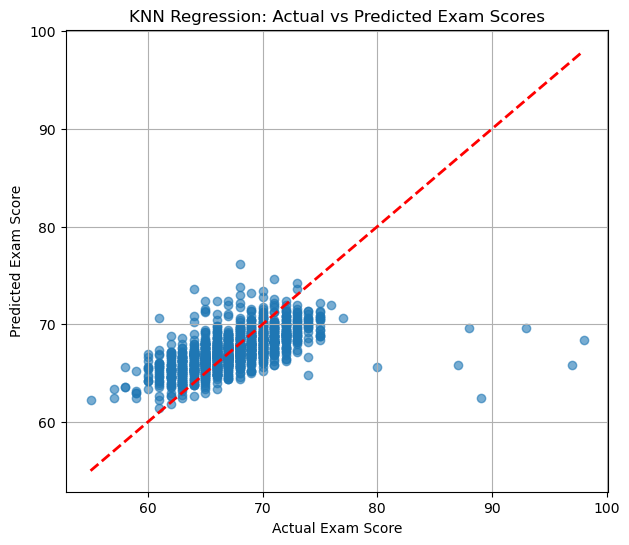

In [20]:
# Visualize actual vs predicted Exam_Score

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)

plt.title("KNN Regression: Actual vs Predicted Exam Scores")
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.grid(True)
plt.show()


## Saving and Loading the Model

Now that our model is trained and performing reasonably well, we don’t want to retrain it every time we need to make predictions.

To **reuse** a trained machine learning model later, we can **save it to a file**, a process called *model serialization*.  
When we need it again, we can simply **load it back** into memory and make new predictions instantly.  

This is very common in real-world applications, for example, when you train a model once and deploy it in a web app or mobile service.

### What do we need to store?

We typically store:
1. The **trained model** itself (so it retains the learned relationships).  
2. The **scaler**, if we used feature scaling, because any new data must be transformed the same way as the training data before prediction.

### How can we save and load the model?

We can use the [`joblib`](https://joblib.readthedocs.io/en/latest/generated/joblib.dump.html) library (a dependency of scikit-learn) to save and load models.

**Example:**

```python
from joblib import dump, load

# Save the trained model and the scaler
dump(knn_reg, "knn_model.joblib")
dump(scaler, "scaler.joblib")

print("Model and scaler saved successfully!")
```


In [21]:
from joblib import dump, load

# Save the trained KNN model and the fitted scaler
dump(knn_reg, "knn_model.joblib")
dump(scaler, "scaler.joblib")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [22]:
import pandas as pd
from joblib import load

# Load the saved model and scaler
knn_reg_loaded = load("knn_model.joblib")
scaler_loaded = load("scaler.joblib")

# Example: new student data (must include all feature columns)
new_student = pd.DataFrame({
    "Hours_Studied": [22],
    "Attendance": [90],
    "Sleep_Hours": [7],
    "Previous_Scores": [72],
    "Tutoring_Sessions": [2],
    "Physical_Activity": [3],
    "Parental_Involvement_Low": [0],
    "Parental_Involvement_Medium": [1],
    "Access_to_Resources_Low": [0],
    "Access_to_Resources_Medium": [1],
    "Extracurricular_Activities_Yes": [1],
    "Motivation_Level_Low": [0],
    "Motivation_Level_Medium": [1],
    "Internet_Access_Yes": [1],
    "Family_Income_Low": [0],
    "Family_Income_Medium": [1],
    "Teacher_Quality_Low": [0],
    "Teacher_Quality_Medium": [1],
    "School_Type_Public": [1],
    "Peer_Influence_Neutral": [0],
    "Peer_Influence_Positive": [1],
    "Learning_Disabilities_No": [1],
    "Learning_Disabilities_Yes": [0],
    "Parental_Education_Level_High School": [1],
    "Parental_Education_Level_Postgraduate": [0],
    "Distance_from_Home_Moderate": [1],
    "Distance_from_Home_Near": [0],
    "Gender_Male": [1]
})

# Put the columns in the order of X, the one the scaler and the model were trained on:
# a column your encoding does not have is dropped, and a missing one is filled with 0
new_student = new_student.reindex(columns=X.columns, fill_value=0)

# Apply the same scaling used during training
new_student_scaled = scaler_loaded.transform(new_student)

# Predict the exam score
predicted_score = knn_reg_loaded.predict(new_student_scaled)
print(f"Predicted Exam Score: {predicted_score[0]:.2f}")


Predicted Exam Score: 69.60


## Step 7 - Feature Engineering

So far, your model has been using **all available features** to make predictions.  
Not every feature helps the model: some are **irrelevant**, and some work against prediction quality.

In this step, you'll explore how **feature selection** affects your model's performance.  
Use your understanding of the data (from SQL exploration or domain knowledge) to decide which features to keep or remove.

### Your task:
- Experiment with **different subsets of features** and observe how the model’s performance changes (e.g., lower MAE for regression).
- Clearly explain **why** you chose to include or exclude certain features.
- Report and discuss **how these choices impacted** your KNN model’s results.

> This step is **unguided**: you choose the approach. Document your reasoning and your results in the notebook.


In [23]:
# your code and explanations can be added in the cells below..
# Remove School Type features
dataset_new = dataset_encoded.drop(
    columns=["School_Type_Private", "School_Type_Public"]
)

# Check the remaining features
print(dataset_new.columns)


Index(['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
       'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score',
       'Parental_Involvement_High', 'Parental_Involvement_Low',
       'Parental_Involvement_Medium', 'Access_to_Resources_High',
       'Access_to_Resources_Low', 'Access_to_Resources_Medium',
       'Extracurricular_Activities_No', 'Extracurricular_Activities_Yes',
       'Motivation_Level_High', 'Motivation_Level_Low',
       'Motivation_Level_Medium', 'Internet_Access_No', 'Internet_Access_Yes',
       'Family_Income_High', 'Family_Income_Low', 'Family_Income_Medium',
       'Teacher_Quality_High', 'Teacher_Quality_Low', 'Teacher_Quality_Medium',
       'Peer_Influence_Negative', 'Peer_Influence_Neutral',
       'Peer_Influence_Positive', 'Learning_Disabilities_No',
       'Learning_Disabilities_Yes', 'Parental_Education_Level_College',
       'Parental_Education_Level_High School',
       'Parental_Education_Level_Postgraduate', 'Distance_from_Home

In [24]:
# Separate features and target
X_new = dataset_new.drop(columns=["Exam_Score"])
y_new = dataset_new["Exam_Score"]

# Split the new dataset into training and test sets
X_train_new,X_test_new,y_train_new,y_test_new = train_test_split(X_new,y_new,test_size=0.20,random_state=42)

In [25]:
# Scale the new features
scaler_new = StandardScaler()
scaler_new.fit(X_train_new)

X_train_new_scaled = scaler_new.transform(X_train_new)
X_test_new_scaled = scaler_new.transform(X_test_new)

In [26]:
# Create and train the new KNN model
knn_new = KNeighborsRegressor(n_neighbors=5)
knn_new.fit(X_train_new_scaled, y_train_new)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [27]:
# Make predictions with the new model
y_pred_new = knn_new.predict(X_test_new_scaled)

# Calculate MAE and RMSE
print("New MAE:", mean_absolute_error(y_test_new, y_pred_new))
print("New RMSE:", mean_squared_error(y_test_new, y_pred_new) ** 0.5)

New MAE: 2.065506807866868
New RMSE: 3.0235835507975555


We removed School Type because we thought it might not be very important for predicting exam scores. After removing it, the MAE decreased from 2.1325 to 2.0655 and the RMSE decreased from 3.0784 to 3.0236. This shows that removing School Type slightly improved our model's performance.

In [28]:
# Remove School Type and Gender features
dataset_new2 = dataset_encoded.drop(
    columns=["School_Type_Private", "School_Type_Public",
             "Gender_Female", "Gender_Male"]
)

# Check the remaining features
print(dataset_new2.columns)

Index(['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
       'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score',
       'Parental_Involvement_High', 'Parental_Involvement_Low',
       'Parental_Involvement_Medium', 'Access_to_Resources_High',
       'Access_to_Resources_Low', 'Access_to_Resources_Medium',
       'Extracurricular_Activities_No', 'Extracurricular_Activities_Yes',
       'Motivation_Level_High', 'Motivation_Level_Low',
       'Motivation_Level_Medium', 'Internet_Access_No', 'Internet_Access_Yes',
       'Family_Income_High', 'Family_Income_Low', 'Family_Income_Medium',
       'Teacher_Quality_High', 'Teacher_Quality_Low', 'Teacher_Quality_Medium',
       'Peer_Influence_Negative', 'Peer_Influence_Neutral',
       'Peer_Influence_Positive', 'Learning_Disabilities_No',
       'Learning_Disabilities_Yes', 'Parental_Education_Level_College',
       'Parental_Education_Level_High School',
       'Parental_Education_Level_Postgraduate', 'Distance_from_Home

In [29]:
# Separate features and target
X_new2 = dataset_new2.drop(columns=["Exam_Score"])
y_new2 = dataset_new2["Exam_Score"]

# Split the new dataset into training and test sets
X_train_new2, X_test_new2, y_train_new2, y_test_new2 = train_test_split(X_new2, y_new2, test_size=0.20, random_state=42)

In [30]:
# Scale the new features
scaler_new2 = StandardScaler()
scaler_new2.fit(X_train_new2)

X_train_new2_scaled = scaler_new2.transform(X_train_new2)
X_test_new2_scaled = scaler_new2.transform(X_test_new2)

In [31]:
# Create and train the new KNN model
knn_new2 = KNeighborsRegressor(n_neighbors=5)
knn_new2.fit(X_train_new2_scaled, y_train_new2)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [32]:
# Make predictions with the new model
y_pred_new2 = knn_new2.predict(X_test_new2_scaled)

# Calculate MAE and RMSE
print("New MAE:", mean_absolute_error(y_test_new2, y_pred_new2))
print("New RMSE:", mean_squared_error(y_test_new2, y_pred_new2) ** 0.5)

New MAE: 2.0735249621785177
New RMSE: 3.0397069689171534


In our second experiment, we removed both School Type and Gender features to see how they affect the KNN model's performance. The MAE was 2.0735 and the RMSE was 3.0397. These results were slightly worse than removing only School Type, but still better than using all features. Therefore, removing only School Type gave us the best results among the three models we tested.